# N146 — H1 loss and RankMe control with prediction margins

We keep N145's current-image loss, rolling health measurements, original parent,
two-output state predictor, one-image updates and H1 rate choice. The change is
the constraint: replace a five-unit RankMe gain with a zero floor plus an
empirically calibrated prediction margin. Two adaptive sensitivity arms use
small positive rank floors of 0.001 and 0.005. N145 remains intact.

This is a **health-only exploratory online pilot**, not a qualified guarantee
of monotonic health or downstream performance. No task panels, labels, linear
probes, kNN or fine-tuning are loaded. The predictor learns online in the three
adaptive arms, after each actually executed positive-rate update. The frozen
arm never adapts. Skips and untried actions never supply online learning targets.

## Measurement and actions

Actions remain {skip, quarter, full} of ORIGINAL nominal LR 0.0001, giving
physical rates {0, 0.000025, 0.0001}. A skip leaves learner and optimizer alone.
No H2 planning, performance rollback, exploration, quotas or compulsory updates.
Numerical failures stop at the last intact checkpoint.

L is the incoming image's reconstruction loss, with identical assay pixels and
MAE masks before and after its update. R is raw RankMe of the latest 256 received
images, including the incoming image, encoded with the respective pre/post
models. Each path starts with 255 no-training arrivals to fill the window.
Membership is identical across candidates at a decision and advances even on
skips. The population rank is not mislabeled as the rank of a single image vector.

Incoming-image plots include actual before/after reconstruction, paired loss
change, before/after rolling rank, paired rank change, pre-action image embedding
norm and cosine to the window mean. Fixed-bank loss, rank, variance/covariance,
CKA/cosine drift and norm remain separate common-population health readouts.

## Predicted gains, empirical margins and score

Predicted gain is current_L - predicted_L for loss and predicted_R - current_R
for rank. Calibration residual is **predicted gain minus actual gain** for BOTH
metrics. Positive residual means overoptimistic prediction.

For each of the two positive rates and each metric, freeze the nonnegative
90th percentile of these residuals, using the higher empirical order statistic.
This quantile is declared before collecting the new margin data and is not
chosen to achieve an admission rate. Negative quantiles are clamped to zero;
hold has exact zero margins. Record per-clip residual summaries as well.

An adaptive or frozen controller admits a candidate only if BOTH:

- predicted_loss_gain - loss_margin[action] > 0.001;
- predicted_rank_gain - rank_margin[action] > rank_floor.

The main rank floor is 0; sensitivities are 0.001 and 0.005 RAW rank units.
Nonphysical forecasts are ineligible. Among feasible actions minimize the
unchanged score predicted_L/current_L + current_R/predicted_R; exact ties choose
the smaller rate. If none qualify, skip. No margins are reduced to escape stalls.

These are empirical margins, NOT formal confidence bounds. The two marginal
90th percentiles do not imply 90% joint protection. Correlated video frames,
selected actions, online predictor adaptation and distribution shift also
prevent a nominal coverage guarantee. Margins stay fixed during the pilot;
actual violations, forecast residuals and input-range excursions are reported.

## Separate predictor training, margin calibration and online pilot

Reuse N145's frozen TRAIN predictor and sufficient statistics, the same 29 input
coordinates, TRAIN input/target transforms, and alpha=1 previously chosen on
N145 validation. Do not refit it on N145 test or on margin-calibration outcomes.
The online half-life remains 256 successful positive updates.

Use the first **12 previously reserved N106 clips** (1,152 arrivals) exclusively
for new margin calibration. These clips are disjoint from all N145 predictor
training/validation/test clips and from the online pilot. Restart the original
neural learner/Adam parent; collect hold/quarter/full outcomes from matched
complete states and paired image seeds; retain a predeclared balanced mixed
action for the continuing calibration path. There are 897 measured origins
after window fill and 1,794 actual positive branch updates. The first measured
clip is partial, leaving ten clips contributing residuals. Outcomes are used
only to set margins and describe calibration behavior, never to change the head.

Freeze and hash the margins before any online run. A replay on these same
calibration branches is descriptive and is not an independent validation result.

The next **96 disjoint reserved clips** provide 9,216 ordered online arrivals
per arm. All seven arms restart the same original neural learner/Adam parent
and use the same image/view seeds. Queue: adaptive H1 floor 0, frozen H1 floor 0,
adaptive H1 floor .001, adaptive H1 floor .005, freeze, always-quarter, always-full.
Only the adaptive arms modify their own predictor. All three adaptive heads
start from identical offline weights/statistics. Immutable shadows predict the
same actual states/actions to assess adaptation without comparing different paths.

Fixed-rate controls intentionally bypass the guard. The pilot runs regardless
of calibration admission count: an all-skip trajectory is an explicit diagnostic
outcome. N145's one-true-positive gate is not reused as a safety certificate.
Engineering validity gates execution; no scientific reliability claim is made.
There is no automatic expansion beyond 9,216 arrivals or best-checkpoint selection.
One parent and one paired randomness family on previously inspected development
video cannot establish population efficacy. Margins and settings are not selected
using pilot outcomes. Random-budget and loss-bank ablations remain later work.

## Reporting, checkpointing and checks

Save complete learner/optimizer/RNG state, predictor sufficient statistics and
trace every 96 arrivals; retain two generations per path. Refresh this notebook,
Markdown and live HTML at each commit; the HTML reloads every 20 seconds. Evaluate
the untouched fixed bank at the parent and every 384 arrivals. Preserve actual
failed-constraint updates in the live lineage and in predictor feedback.

Report all arm coverages, physical LR dose, predictor updates, longest skip runs,
actual loss/rank violations, strict minimum-gain failures, positive-action
RMSE/MAE versus persistence and frozen shadow, calibration margins, per-clip
summaries, and operational/evaluation costs. Identity skips are excluded from
forecast RMSE; no accepted updates means undefined error, not perfect prediction.
Checkpoint measurements and frames are correlated, not independent replicas.

GPU checks verify exact resumed/uninterrupted adaptive, frozen and freeze runs,
matched calibration collection and repeatable assays. A permissive threshold
appears ONLY in isolated engineering work to exercise adaptive updates. No such
override exists in the scientific pilot. Stop requests and <1 GiB disk reserve
stop safely; errors remain visible. No automatic restart or threshold relaxation.


Status: **complete** · updated UTC `2026-11-04T12:35:40.850256+00:00`.

Current path: **preparation / verification**. Calibration: 1,152 arrivals; online pilot: 9,216 per arm.

GPU/exact-resume preflight: **passed**.

Frozen prediction margins (raw metric units; outputs ordered loss, rank):

| Action | Loss margin | RankMe margin |
|---|---:|---:|
| 0 × nominal | 0 | 0 |
| 0.25 × nominal | 0.006918726 | 0.008796242 |
| 1 × nominal | 0.02903093 | 0.03566319 |

Estimated from 897 matched origins on 10 contributing clips. Margins stay fixed online; they are not a joint coverage guarantee.

Calibration replay (same data used to estimate margins; **not held-out qualification**):

| Rank floor | Selected | Actual both gains | Rank decreases | Loss increases |
|---|---:|---:|---:|---:|
| 0.0 | 55 | 29 | 26 | 0 |
| 0.001 | 43 | 19 | 21 | 0 |
| 0.005 | 16 | 3 | 11 | 0 |

| Path | Arrivals | Measured origins | Retained learner updates | Predictor updates | Committed optimizer steps |
|---|---:|---:|---:|---:|---:|
| offline/margin_calibration | 1152/1152 | 897 | 598 | 0 | 1794 |
| online/adaptive_h1 | 9216/9216 | 8961 | 18 | 18 | 18 |
| online/adaptive_rank001 | 9216/9216 | 8961 | 24 | 24 | 24 |
| online/adaptive_rank005 | 9216/9216 | 8961 | 16 | 16 | 16 |
| online/always_full | 9216/9216 | 8961 | 8961 | 0 | 8961 |
| online/always_quarter | 9216/9216 | 8961 | 8961 | 0 | 8961 |
| online/freeze | 9216/9216 | 8961 | 0 | 0 | 0 |
| online/frozen_h1 | 9216/9216 | 8961 | 21 | 0 | 21 |

Offline updates collect paired margin data on a mixed-action path. They are not constrained-controller admissions. Each online arm starts from the original parent.

Online health and guard diagnostics:

| Arm | Latest fixed loss | Latest fixed rank | Health violations | Minimum-gain failures | Longest skip run | LR multiplier sum |
|---|---:|---:|---:|---:|---:|---:|
| online/adaptive_h1 (audit 9216) | 0.960474 | 4.58767 | 4 | 4 | 2494 | 18.000 |
| online/adaptive_rank001 (audit 9216) | 1.04193 | 3.21488 | 4 | 5 | 1057 | 22.500 |
| online/adaptive_rank005 (audit 9216) | 0.927184 | 4.63742 | 3 | 4 | 2494 | 16.000 |
| online/always_full (audit 9216) | 1.01356 | 3.55785 | 4958 | 6459 | 0 | 8961.000 |
| online/always_quarter (audit 9216) | 0.842524 | 4.94042 | 4624 | 6663 | 0 | 2240.250 |
| online/freeze (audit 9216) | 1.09674 | 3.28387 | 0 | 0 | 8961 | 0.000 |
| online/frozen_h1 (audit 9216) | 0.971188 | 4.70545 | 7 | 7 | 2494 | 21.000 |

Fixed-rate controls bypass the gate deliberately. Skip-run lengths exclude the initial 255-image window fill. Partial arms have different coverage.

Positive-action RMSE (loss, RankMe), excluding identity skips:

| Arm | Updates | Active predictor | Frozen shadow on same states/actions | Persistence |
|---|---:|---|---|---|
| online/adaptive_h1 | 18 | 0.02428, 0.045859 | 0.025009, 0.046054 | 0.043133, 0.074404 |
| online/adaptive_rank001 | 24 | 0.025248, 0.033011 | 0.031079, 0.041006 | 0.018027, 0.010008 |
| online/adaptive_rank005 | 16 | 0.025219, 0.078847 | 0.026475, 0.081941 | 0.046149, 0.11797 |
| online/always_full | 8961 | 0.018002, 0.032735 | 0.018002, 0.032735 | 0.006992, 0.02724 |
| online/always_quarter | 8961 | 0.0041788, 0.010668 | 0.0041788, 0.010668 | 0.0036018, 0.010484 |
| online/freeze | 0 | undefined | undefined | undefined |
| online/frozen_h1 | 21 | 0.025102, 0.046442 | 0.025102, 0.046442 | 0.039879, 0.077125 |

Completed isolated engineering optimizer steps: 54. They are excluded from scientific totals above.

Accumulated operation times (seconds; exclude checkpoint/report overhead):

- measurement: 2043.36
- training: 359.83
- prediction: 16.42
- adaptation: 0.01
- fixed_audit: 10.80

No automatic full-stream expansion. Calibration, online operations and engineering are distinct costs.


In [1]:
from pathlib import Path
import json
root = Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\margin-health-h1\\20261104-n146')
summary = json.loads((root / 'report-summary.json').read_text())
print(json.dumps(summary, indent=2))


{
  "status": {
    "stage": "complete",
    "running": false,
    "pid": 17008,
    "updated_utc": "2026-11-04T12:35:40.850256+00:00"
  },
  "margins": {
    "quantile": 0.9,
    "method": "higher empirical quantile, clamped nonnegative",
    "margins": [
      [
        0.0,
        0.0
      ],
      [
        0.006918726014154553,
        0.00879624202619489
      ],
      [
        0.02903092822935527,
        0.03566318852532757
      ]
    ],
    "outputs": [
      "loss gain",
      "RankMe gain"
    ],
    "actions": [
      0.0,
      0.25,
      1.0
    ],
    "origins": 897,
    "positive_branches": 1794,
    "contributing_clips": 10,
    "mean_overprediction": [
      [
        0.0,
        0.0
      ],
      [
        0.003465319094919641,
        0.005265371589436609
      ],
      [
        0.014682824285594597,
        0.022209315860694093
      ]
    ],
    "by_clip": {
      "2": {
        "origins": 33,
        "overprediction_quantile": [
          [
            0.

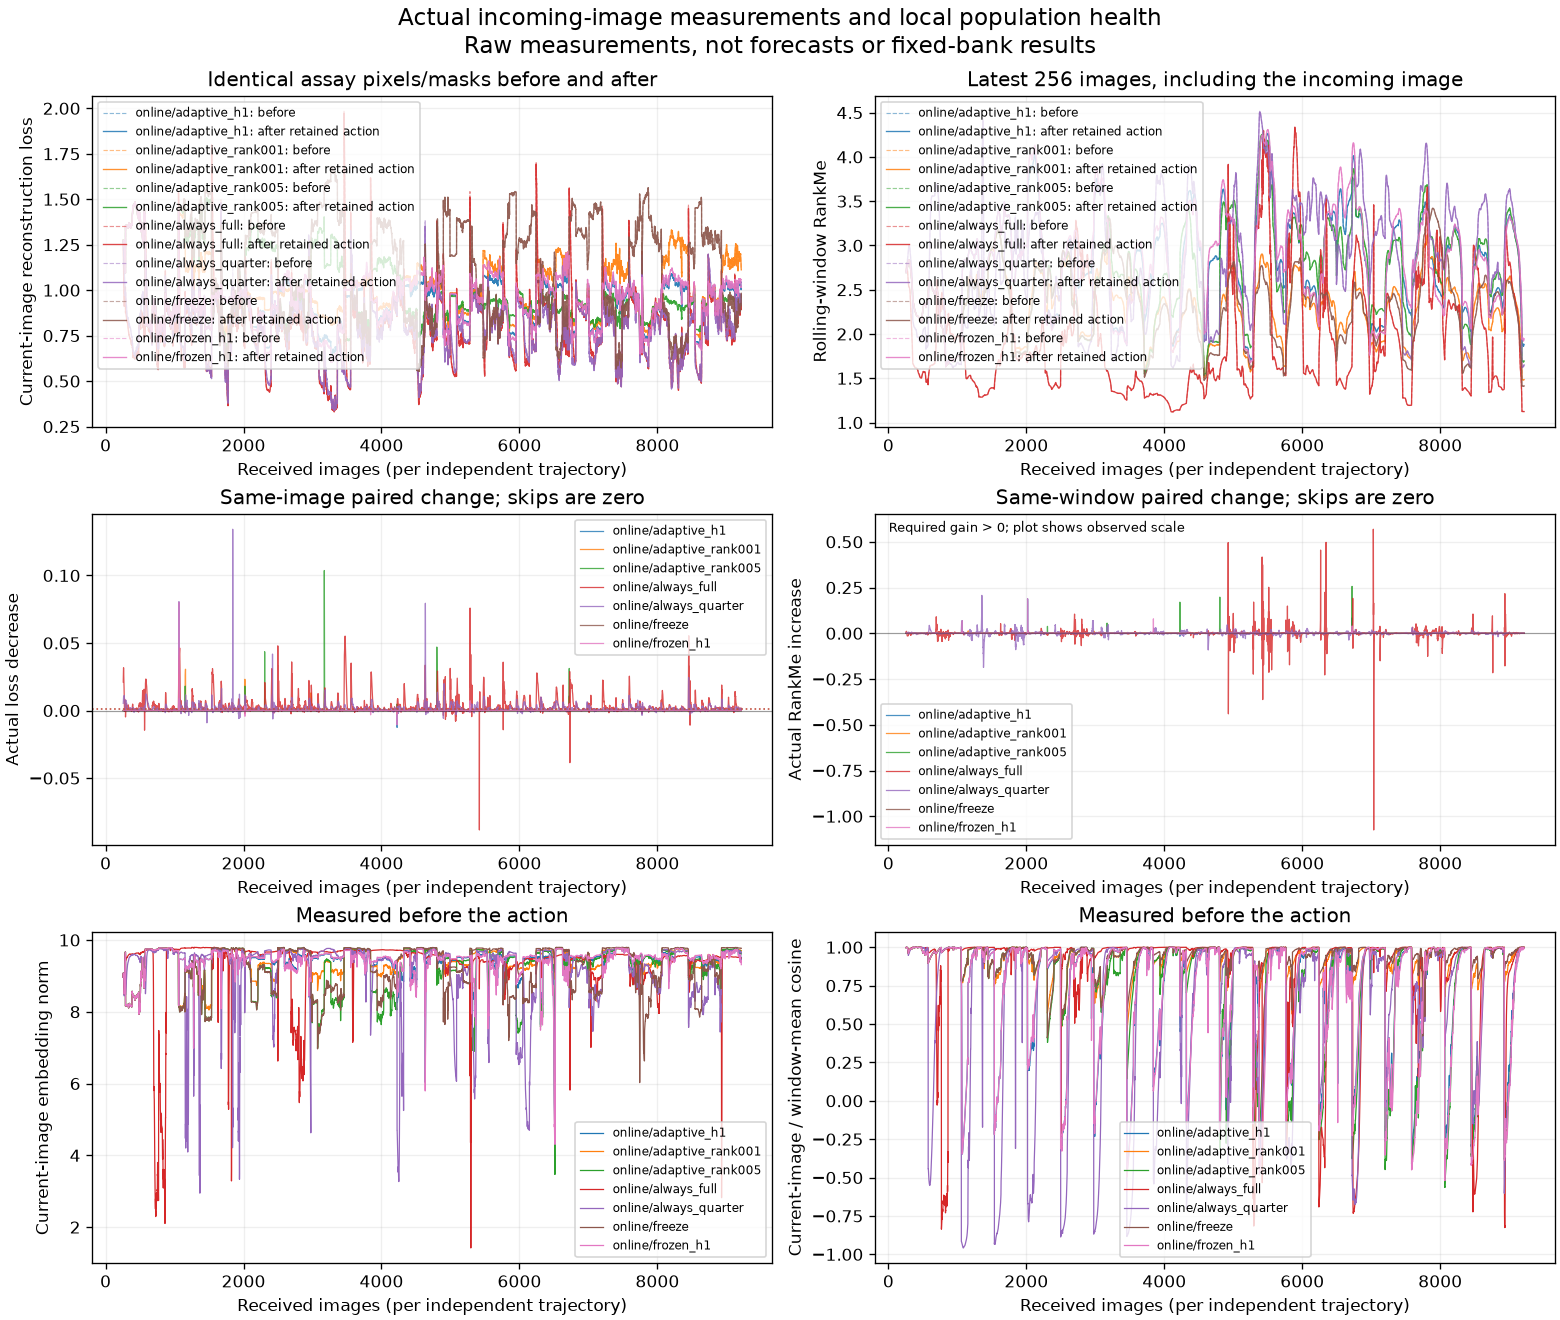

In [2]:
from IPython.display import Image, display
display(Image(filename=str(root / 'current-image-health.png')))


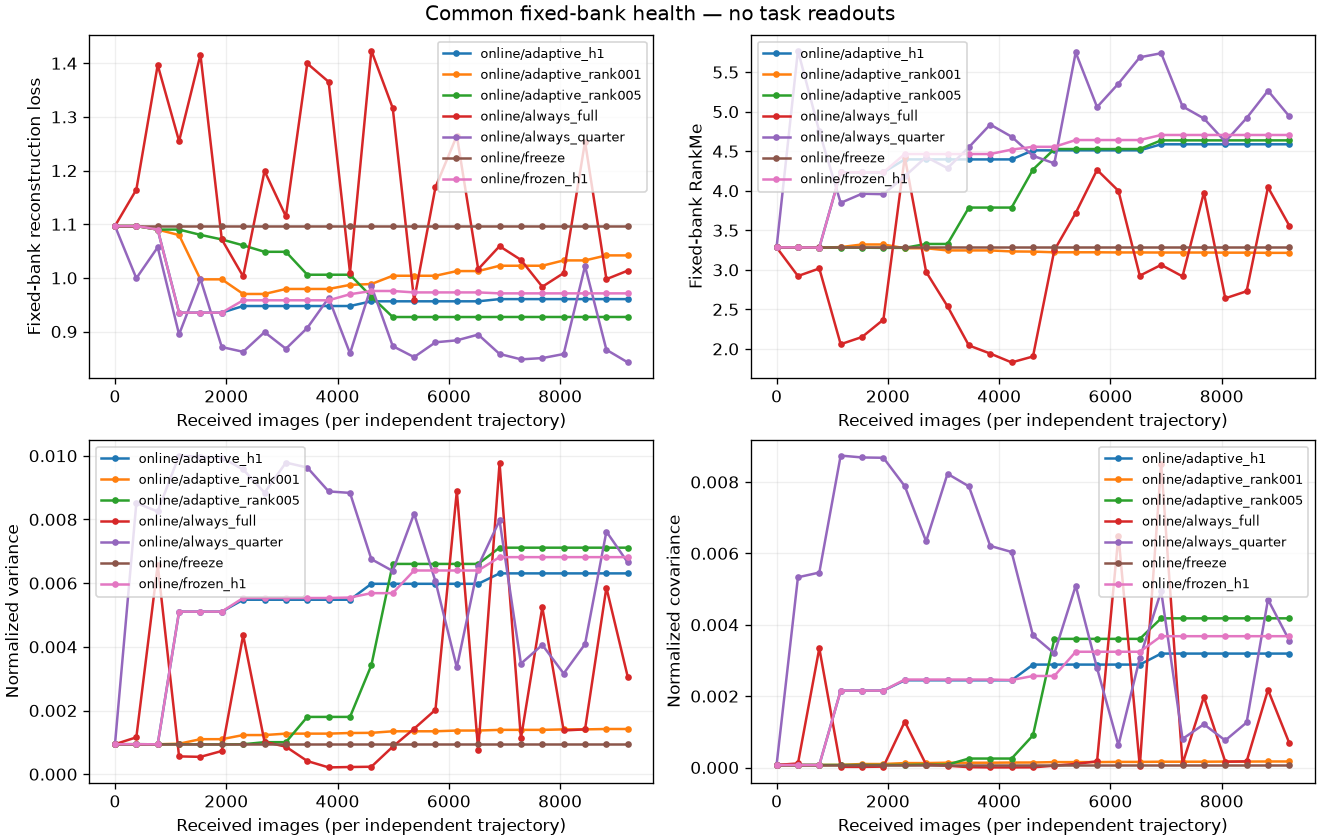

In [3]:
from IPython.display import Image, display
display(Image(filename=str(root / 'health.png')))


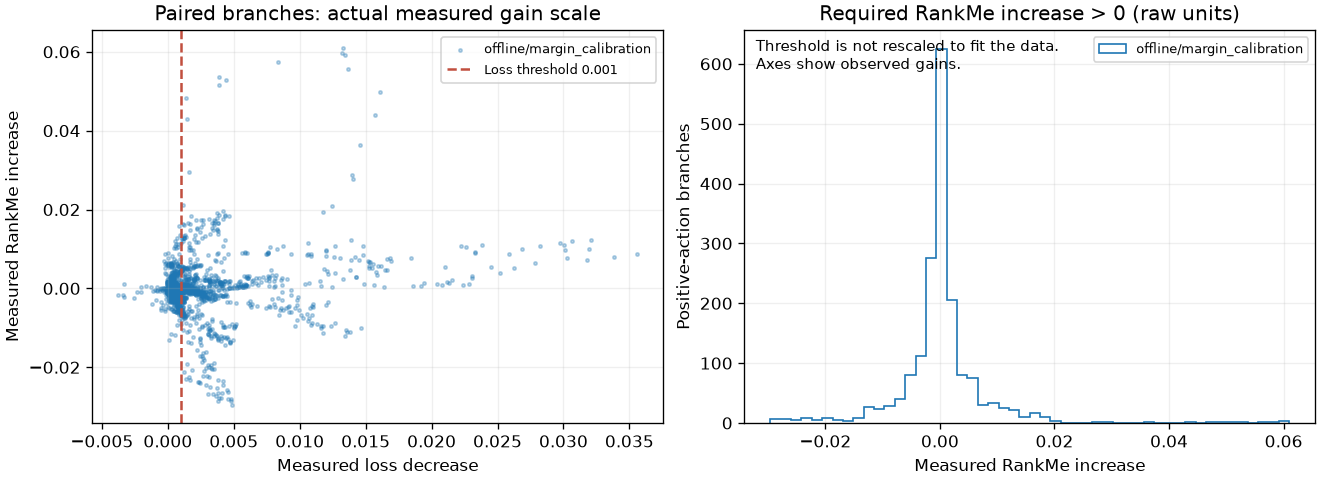

In [4]:
from IPython.display import Image, display
display(Image(filename=str(root / 'paired-gains.png')))
